<h1>Анализ игрового рынка для интернет-магазина «Стримчик»</h1>

Представим, что я - аналитик в интернет-магазине «Стримчик», который продаёт по всему миру компьютерные игры. Из открытых источников доступны исторические данные о продажах игр, оценки пользователей и экспертов, жанры и платформы (например, Xbox или PlayStation). В рамках этого проекта мне нужно выявить определяющие успешность игры закономерности. Это позволит сделать ставку на потенциально популярный продукт и спланировать рекламные кампании.

Были предоставлены данные до 2016 года. Сейчас декабрь 2016 г., и мы планируем кампанию на 2017-й. 

В наборе данных попадается аббревиатура ESRB (Entertainment Software Rating Board) — это ассоциация, определяющая возрастной рейтинг компьютерных игр. ESRB оценивает игровой контент и присваивает ему подходящую возрастную категорию:

- «EC» («Early childhood») — «Для детей младшего возраста»
- «E» («Everyone») — «Для всех» (до 1998 обозначался как «K-A» («Kids to Adults»))
- «E10+» («Everyone 10 and older»)
- «T» («Teen») — «Подросткам»
- «M» («Mature») — «Для взрослых»
- «AO» («Adults Only 18+») — «Только для взрослых»
- «RP» («Rating Pending») — «Рейтинг ожидается»
- «RP 17+» («Rating Pending») — «Рейтинг ожидается - примерно 17+»

В рамках данного исследования я планирую:

1. **Подготовить данные:** заменить названия столбцов, преобразовать данные в нужные типы, обработать пропуски, посчитать суммарные продажи во всех регионах и записать их в отдельный столбец.

</n>

2. **Провести исследовательский анализ данных**
    - Посмотреть, сколько игр выпускалось в разные годы.
    - Посмотреть, как менялись продажи по платформам.
    - Выяснить какие платформы лидируют по продажам, растут или падают. Выбрать несколько потенциально прибыльных платформ.
    - Посмотреть, как влияют на продажи внутри одной платформы отзывы пользователей и критиков.
    - Построить диаграмму рассеяния и посчитать корреляцию между отзывами и продажами.
    - Выяснить самые прибыльные жанры. 

</n>

3. **Составить портрет пользователя каждого региона:**
    
    Определить для пользователя каждого региона (*NA, EU, JP*):
    
    - Самые популярные платформы (топ-5).
    - Самые популярные жанры (топ-5).
    - Влияет ли рейтинг ESRB на продажи в отдельном регионе?

</n>

4.  **Проверить гипотезы**
- Средние пользовательские рейтинги платформ *Xbox One* и *PC* одинаковые;
- Средние пользовательские рейтинги жанров *Action* (англ. «действие», экшен-игры) и *Sports* (англ. «спортивные соревнования») разные.

**Шаг 1. Открытие файла с данными и изучение общей информации**

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats as st
import numpy as np
import seaborn as sns

In [2]:
games = pd.read_csv('games.csv')

In [3]:
games.head()

,Name,Platform,Year_of_Release,Genre,NA_sales,EU_sales,JP_sales,Other_sales,Critic_Score,User_Score,Rating
0,Wii Sports,Wii,2006.0,Sports,41.36,28.96,3.77,8.45,76.0,8,E
1,Super Mario Bros.,NES,1985.0,Platform,29.08,3.58,6.81,0.77,NaN,NaN,NaN
2,Mario Kart Wii,Wii,2008.0,Racing,15.68,12.76,3.79,3.29,82.0,8.3,E
3,Wii Sports Resort,Wii,2009.0,Sports,15.61,10.93,3.28,2.95,80.0,8,E
4,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,11.27,8.89,10.22,1.00,NaN,NaN,NaN


In [4]:
games.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16715 entries, 0 to 16714
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Name             16713 non-null  object 
 1   Platform         16715 non-null  object 
 2   Year_of_Release  16446 non-null  float64
 3   Genre            16713 non-null  object 
 4   NA_sales         16715 non-null  float64
 5   EU_sales         16715 non-null  float64
 6   JP_sales         16715 non-null  float64
 7   Other_sales      16715 non-null  float64
 8   Critic_Score     8137 non-null   float64
 9   User_Score       10014 non-null  object 
 10  Rating           9949 non-null   object 
dtypes: float64(6), object(5)
memory usage: 1.4+ MB


После первичного осмотра данных можно сказать, что в таблице присутвуют данные о 16715 играх, которые планируется более подробно изучить в рамках данного анализа. 
Также в таблице данные хранятся в 11 столбцах, что обозначает каждый из них описано ниже. Также сразу заметно, что данные в столбцах заполнены не равномерно, присутствуют пропуски.

Обозначение данных в таблице: 

- name - название игры
- platform — платформа
- year_of_release	— год выпуска
- genre	— жанр игры
- na_sales	— продажи в Северной Америке (миллионы проданных копий)
- eu_sales	— продажи в Европе (миллионы проданных копий)
- jp_sales	— продажи в Японии (миллионы проданных копий)
- other_sales	— продажи в других странах (миллионы проданных копий)
- critic_score	— оценка критиков (максимум 100)
- user_score	— оценка пользователей (максимум 10)
- rating	— рейтинг от организации ESRB
- total_sales - общие продажи по всем регионам

**Шаг 2. Подготовка данных**
- Заменить названия столбцов (привести к нижнему регистру); 
- Преобразовать данные в нужные типы. Описать, в каких столбцах заменили тип данных и почему; 
- Обработать пропуски при необходимости:
    - Объяснить, почему заполнили пропуски определённым образом или почему не стали это делать;
    - Описать причины, которые могли привести к пропускам;
    - Обратить внимание на аббревиатуру 'tbd' в столбце с оценкой пользователей. Отдельно разобрать это значение и описать, как его обработать; 
- Посчитать суммарные продажи во всех регионах и запишите их в отдельный столбец. 

Надо привести названия столбцов к нижнему регистру и поменять типы данных.

Для начала надо привести названия столбцов к нижнему регистру

In [5]:
games.columns

Index(['Name', 'Platform', 'Year_of_Release', 'Genre', 'NA_sales', 'EU_sales',
       'JP_sales', 'Other_sales', 'Critic_Score', 'User_Score', 'Rating'],
      dtype='object')

In [6]:
games.columns = map(str.lower, games.columns)

In [7]:
games.columns

Index(['name', 'platform', 'year_of_release', 'genre', 'na_sales', 'eu_sales',
       'jp_sales', 'other_sales', 'critic_score', 'user_score', 'rating'],
      dtype='object')

Теперь надо привести в корректному типу данных столбцы:
1. year_of_release -> int. Так как год выпуска выражается только целыми числами. 
2. user_score -> float. Так как оценка пользователя - это числовое значение. 

Прежде чем привести столбец к нужному типу данных надо разобраться с пропусками. Причиной пропусков могла стать техническая ошибка, либо же в открытых источников нет точный даты публикации той или иной игры.

In [8]:
games['year_of_release'].isna().sum()

269

In [9]:
games[games['year_of_release'].isna()]

,name,platform,year_of_release,genre,na_sales,eu_sales,jp_sales,other_sales,critic_score,user_score,rating
183,Madden NFL 2004,PS2,NaN,Sports,4.26,0.26,0.01,0.71,94.0,8.5,E
377,FIFA Soccer 2004,PS2,NaN,Sports,0.59,2.36,0.04,0.51,84.0,6.4,E
456,LEGO Batman: The Videogame,Wii,NaN,Action,1.80,0.97,0.00,0.29,74.0,7.9,E10+
475,wwe Smackdown vs. Raw 2006,PS2,NaN,Fighting,1.57,1.02,0.00,0.41,NaN,NaN,NaN
609,Space Invaders,2600,NaN,Shooter,2.36,0.14,0.00,0.03,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...
16373,PDC World Championship Darts 2008,PSP,NaN,Sports,0.01,0.00,0.00,0.00,43.0,tbd,E10+
16405,Freaky Flyers,GC,NaN,Racing,0.01,0.00,0.00,0.00,69.0,6.5,T
16448,Inversion,PC,NaN,Shooter,0.01,0.00,0.00,0.00,59.0,6.7,M
16458,Hakuouki: Shinsengumi Kitan,PS3,NaN,Adventure,0.01,0.00,0.00,0.00,NaN,NaN,NaN


Так как самостоятельно заполнить год выпуска 269 игр не представляется возможным и в дальнейшем исследовании они не смогут попасть в актуальный период, пропуски решено удалить. После этого я приведу весь столбец к типу int.

In [10]:
games = games.dropna(subset=['year_of_release'])

Проверяю, что пропусков больше нет.

In [11]:
games['year_of_release'].isna().sum()

0

In [12]:
games['year_of_release'] = games['year_of_release'].astype('int')

Проверяю, что тип изменился корректно

In [13]:
games.info()

<class 'pandas.core.frame.DataFrame'>
Index: 16446 entries, 0 to 16714
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   name             16444 non-null  object 
 1   platform         16446 non-null  object 
 2   year_of_release  16446 non-null  int32  
 3   genre            16444 non-null  object 
 4   na_sales         16446 non-null  float64
 5   eu_sales         16446 non-null  float64
 6   jp_sales         16446 non-null  float64
 7   other_sales      16446 non-null  float64
 8   critic_score     7983 non-null   float64
 9   user_score       9839 non-null   object 
 10  rating           9768 non-null   object 
dtypes: float64(5), int32(1), object(5)
memory usage: 1.4+ MB


Теперь надо поменять тип данных в столбце user_score

In [14]:
games['user_score'] = pd.to_numeric(games['user_score'], errors='coerce')

В столбце с оценкой пользователя есть значение tbd, которое расшифровывается как "to be determined", что можно понять как то что оценки нет, поэтому при переводе в другой тип я заменила эти значения на nan. Причиной появления такого обозначения может быть факт того, что игра вышла недавно и оценка еще не была сформирована, или же оценок сейчас недостаточно для выставления общей оценки пользователя. Также нельзя исключать и техническую ошибку. 

In [15]:
games.info()

<class 'pandas.core.frame.DataFrame'>
Index: 16446 entries, 0 to 16714
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   name             16444 non-null  object 
 1   platform         16446 non-null  object 
 2   year_of_release  16446 non-null  int32  
 3   genre            16444 non-null  object 
 4   na_sales         16446 non-null  float64
 5   eu_sales         16446 non-null  float64
 6   jp_sales         16446 non-null  float64
 7   other_sales      16446 non-null  float64
 8   critic_score     7983 non-null   float64
 9   user_score       7463 non-null   float64
 10  rating           9768 non-null   object 
dtypes: float64(6), int32(1), object(4)
memory usage: 1.4+ MB


Теперь надо проверить каждый столбец на пропуски и обработать их при необходимости.

In [16]:
games['name'].isna().sum()

2

In [17]:
games[games['name'].isna()]

,name,platform,year_of_release,genre,na_sales,eu_sales,jp_sales,other_sales,critic_score,user_score,rating
659,NaN,GEN,1993,NaN,1.78,0.53,0.00,0.08,NaN,NaN,NaN
14244,NaN,GEN,1993,NaN,0.00,0.00,0.03,0.00,NaN,NaN,NaN


Об этих двух играх нет практически никакой информации, поэтому эти строки я решаю удалить. Возможно эти строки были заведены в следствие технической ошибки при импорте данных или их формировании, или человек, который вносил эти данные случайно пропустил эти две игры. 

In [18]:
games = games.dropna(subset=['name'])

In [19]:
games.isna().sum()

name                  0
platform              0
year_of_release       0
genre                 0
na_sales              0
eu_sales              0
jp_sales              0
other_sales           0
critic_score       8461
user_score         8981
rating             6676
dtype: int64

In [20]:
games[games['critic_score'].isna()].head()

,name,platform,year_of_release,genre,na_sales,eu_sales,jp_sales,other_sales,critic_score,user_score,rating
1,Super Mario Bros.,NES,1985,Platform,29.08,3.58,6.81,0.77,NaN,NaN,NaN
4,Pokemon Red/Pokemon Blue,GB,1996,Role-Playing,11.27,8.89,10.22,1.00,NaN,NaN,NaN
5,Tetris,GB,1989,Puzzle,23.20,2.26,4.22,0.58,NaN,NaN,NaN
9,Duck Hunt,NES,1984,Shooter,26.93,0.63,0.28,0.47,NaN,NaN,NaN
10,Nintendogs,DS,2005,Simulation,9.05,10.95,1.93,2.74,NaN,NaN,NaN


В столбце с оценкой критиков было обнаружено 8576 пропуска. 

В данном случае нет возможности восполнить пропуски, поэтому я оставлю nan. Причиной пропусков могут быть разнообразные причины: критики могли просто не оценить ту или иную игру, так как сама игра могла быть непопулярной. Или же при формировании таблицы эти данные могли быть утеряны из-за технической ошибки.

In [21]:
games['user_score'].isna().sum()

8981

In [22]:
games[games['user_score'].isna()].head()

,name,platform,year_of_release,genre,na_sales,eu_sales,jp_sales,other_sales,critic_score,user_score,rating
1,Super Mario Bros.,NES,1985,Platform,29.08,3.58,6.81,0.77,NaN,NaN,NaN
4,Pokemon Red/Pokemon Blue,GB,1996,Role-Playing,11.27,8.89,10.22,1.00,NaN,NaN,NaN
5,Tetris,GB,1989,Puzzle,23.20,2.26,4.22,0.58,NaN,NaN,NaN
9,Duck Hunt,NES,1984,Shooter,26.93,0.63,0.28,0.47,NaN,NaN,NaN
10,Nintendogs,DS,2005,Simulation,9.05,10.95,1.93,2.74,NaN,NaN,NaN


Здесь та же ситуация, что и с оценками критиков. В данном случае количество пропусков увеличилось еще и по причине того, что ранее я перевела в пропуски значения ячеек с tbd, причины которых я объяснила выше. Сами же пропуски могут быть объяснены теми же причинами, что и пропуске в столбце с оценками критиков. Возможно техническая ошибка повлияла на оба столбца с оценками одновременно, так как при поверхностном просмотре видно, что строки, в которых отсутствует оценка пользователями, так же не имеют оценки от критиков и рейтинга.

In [23]:
games['rating'].isna().sum()

6676

In [24]:
games['rating'].value_counts()

rating
E       3921
T       2905
M       1536
E10+    1393
EC         8
K-A        3
AO         1
RP         1
Name: count, dtype: int64

Здесь можно заметить, что количество пропусков в колонке с рейтингом занимает практически половину от всех данных. В данном контексте лучшим решением бы было дозапросить эту информацию у заказчика или разработчика, который занимался сбором данных. Но поскольку такой возможности нет, то заменю их на значение None, чтобы оно также отображалось в статистике. Здесь пропуски также можно объяснить технической ошибкой при выгрузке данных. Или же у некоторых игр был просто не опубликован рейтинг ESRB или еще не определен, поэтому при выгрузке из открытых источников эта колонка и не была заполнена.

In [25]:
games['rating'] = games['rating'].fillna('None')

In [26]:
games['rating'].isna().sum()

0

In [27]:
games['rating'].value_counts()

rating
None    6676
E       3921
T       2905
M       1536
E10+    1393
EC         8
K-A        3
AO         1
RP         1
Name: count, dtype: int64

Просмотрев все столбцы на наличие пропусков, я хочу добавить новый столбец для упрощения дальнейшего анализа.

In [28]:
games['total_sales'] = games['na_sales'] + games['eu_sales'] + games['jp_sales'] + games['other_sales']

Добавила новый столбец, где суммировала общие продажи каждой игры.

In [29]:
games.head()

,name,platform,year_of_release,genre,na_sales,eu_sales,jp_sales,other_sales,critic_score,user_score,rating,total_sales
0,Wii Sports,Wii,2006,Sports,41.36,28.96,3.77,8.45,76.0,8.0,E,82.54
1,Super Mario Bros.,NES,1985,Platform,29.08,3.58,6.81,0.77,NaN,NaN,None,40.24
2,Mario Kart Wii,Wii,2008,Racing,15.68,12.76,3.79,3.29,82.0,8.3,E,35.52
3,Wii Sports Resort,Wii,2009,Sports,15.61,10.93,3.28,2.95,80.0,8.0,E,32.77
4,Pokemon Red/Pokemon Blue,GB,1996,Role-Playing,11.27,8.89,10.22,1.00,NaN,NaN,None,31.38


Прежде чем перейти к исследовательскому анализу данных, я хочу проверить данные на дубликаты.

In [30]:
games.duplicated().sum()

0

Поскольку явных дубликатов нет, то перехожу к следующему пункту анализа.

Теперья хочу попробовать найти неявные дубликаты, которые могут быть выявлены, если сравнить строки, в которых могут содержаться одинаковые название, платформа и год релиза.

Этот код создает временный столбец duplicate_check, содержащий кортежи из значений в столбцах name, platform и year_of_release. Затем он проверяет дубликаты в этом столбце и выводит их, если они обнаружены. После проверки временный столбец удаляется.

In [31]:
# Выбераю только нужные столбцы для проверки дубликатов
columns_to_check = ['name', 'platform', 'year_of_release']

In [32]:
# Создаю новый столбец совместных значений для проверки дубликатов
games['duplicate_check'] = games[columns_to_check].apply(tuple, axis=1)

In [33]:
# Проверяю дубликаты и выведем их, если они есть
duplicate_rows = games[games.duplicated(subset='duplicate_check', keep=False)]
if not duplicate_rows.empty:
    print("Найдены неявные дубликаты:")
    print(duplicate_rows)
else:
    print("Неявных дубликатов не найдено.")

Найдены неявные дубликаты:
                name platform  year_of_release   genre  na_sales  eu_sales  \
604    Madden NFL 13      PS3             2012  Sports      2.11      0.22   
16230  Madden NFL 13      PS3             2012  Sports      0.00      0.01   

       jp_sales  other_sales  critic_score  user_score rating  total_sales  \
604         0.0         0.23          83.0         5.5      E         2.56   
16230       0.0         0.00          83.0         5.5      E         0.01   

                  duplicate_check  
604    (Madden NFL 13, PS3, 2012)  
16230  (Madden NFL 13, PS3, 2012)  


Во время проверки на неявные дубликаты нашлась одна строка, которая практически полностью повторяет другую, за исключением продаж, эту строку решено удалить.

In [34]:
# Удалим неявные дубликаты
games = games.drop_duplicates(subset='duplicate_check')

In [35]:
# Удалим временный столбец, который использовали для проверки
games = games.drop(columns=['duplicate_check'])

**Вывод**

Для начала надо было привести все названия столбцов к нижнему регистру и корректному типу данных. 

Столбец "year_of_release" был преобразован в тип данных int, так как год выпуска представлен только целыми числами. 

Столбец user_score был изменен на float, так как оценка пользователя - числовое значение, не строка, как изначально указано. Значения tbd в этом столбце были заменены на nan, поскольку они означают "to be determined", т.е. отсутствие оценки.

Проверены столбцы на пропуски. В столбце name обнаружены два пропуска, информации об этих играх практически не было, поэтому они удалены. В столбце с оценкой критиков и пользователей оставлены 8576 и 9123 пропуска соответственно, так как невозможно восстановить данные. 

В столбце year_of_release также были пропуски, их было решено удалить. Причиной их могли быть технические ошибки или отсутствие точных данных о дате публикации некоторых игр в открытых источниках.

В колонке с рейтингом отсутствуют значения у 6764 строк. Пропуски заменила на значение None, чтобы оно также отображалось в статистике..

Просмотрев все столбцы на наличие дубликатов и убрав один неявный дубликат, я добавила новый столбец, где суммировала общие продажи каждой игры.

<h2>Исследовательский анализ данных</h2>

Сначала я хочу построить диаграмму с распределением игр по годам.

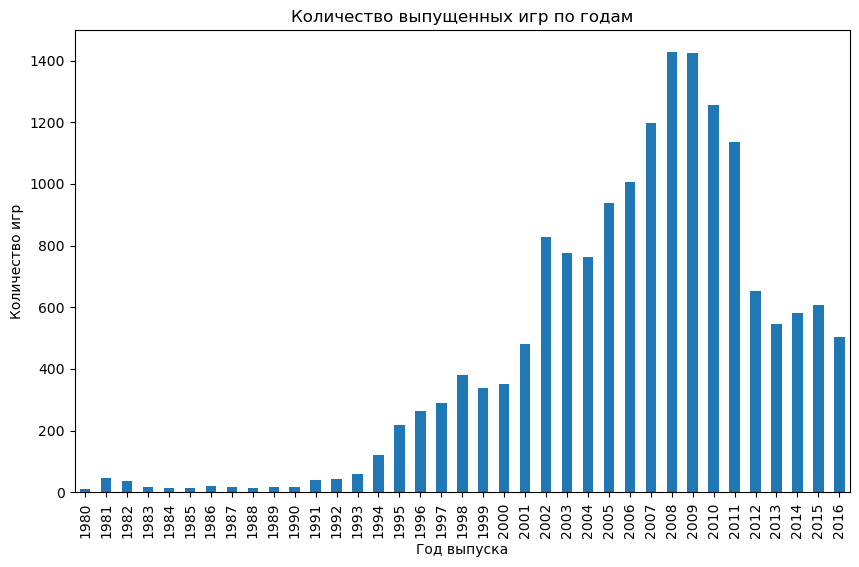

In [36]:
# Группировка данных по годам выпуска, подсчет количества игр и сортировка по году
game_counts_index = games['year_of_release'].value_counts().sort_index()

# Построение диаграммы
game_counts_index.plot.bar(figsize=(10, 6))

# Настройки осей и заголовка диаграммы
plt.xlabel('Год выпуска')
plt.ylabel('Количество игр')
plt.title('Количество выпущенных игр по годам')

# Отображение диаграммы
plt.show()

Как можно заметить из графика, пик выпуска игр пришел на 2008 и 2009 год, после этого их количество пошло на спад. 

Теперь я отсортировала значения по убыванию, чтобы посмотреть какие года были наиболее продуктивными по выпуску игр.

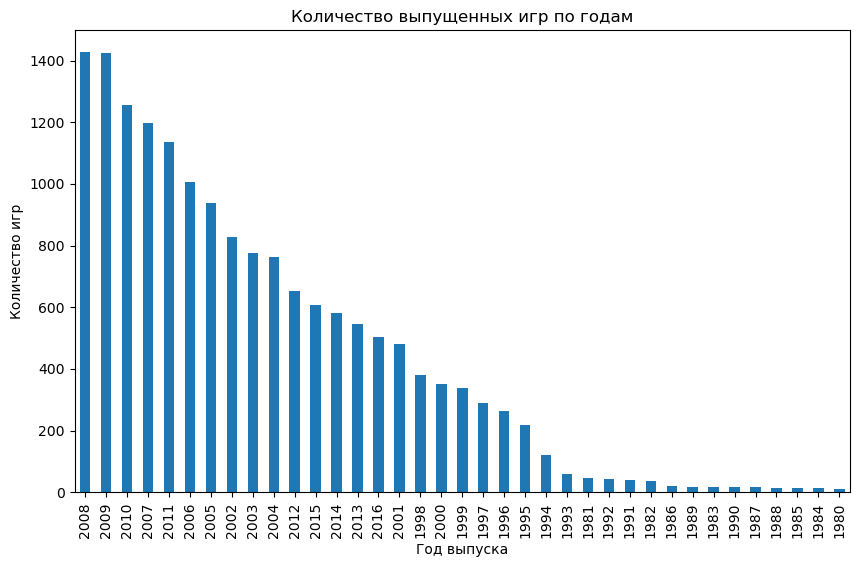

In [37]:
# Группировка данных по годам выпуска, подсчет количества игр и сортировка по количеству выпущенных игр
game_counts_values = games['year_of_release'].value_counts().sort_values(ascending=False)

# Построение диаграммы
game_counts_values.plot.bar(figsize=(10, 6))

# Настройки осей и заголовка диаграммы
plt.xlabel('Год выпуска')
plt.ylabel('Количество игр')
plt.title('Количество выпущенных игр по годам')

# Отображение диаграммы
plt.show()

На графике выше видно, что наиболее активный период выпуска игр пришелся на время после 1995, и даже то количество игр, которые были выпущены в период с 1995 по 2000 значительно меньше, чем игры, которые были выпущены после этого времени. 

<b>Посмотреть, как менялись продажи по платформам. Выбрать платформы с наибольшими суммарными продажами и построить распределение по годам. За какой характерный срок появляются новые и исчезают старые платформы?</b>

Для наиболее корректного ответа на данный вопрос я буду использовать данные по всем годам.

In [38]:
# Группировка данных по платформам и подсчет суммарных продаж
platform_sales = games.groupby('platform')['total_sales'].sum().sort_values(ascending=False)

In [39]:
platform_sales

platform
PS2     1233.56
X360     961.24
PS3      931.33
Wii      891.18
DS       802.78
PS       727.58
PS4      314.14
GBA      312.88
PSP      289.53
3DS      257.81
PC       255.76
GB       254.43
XB       251.57
NES      251.05
N64      218.01
SNES     200.04
GC       196.73
XOne     159.32
2600      86.48
WiiU      82.19
PSV       53.81
SAT       33.59
GEN       28.35
DC        15.95
SCD        1.86
NG         1.44
WS         1.42
TG16       0.16
3DO        0.10
GG         0.04
PCFX       0.03
Name: total_sales, dtype: float64

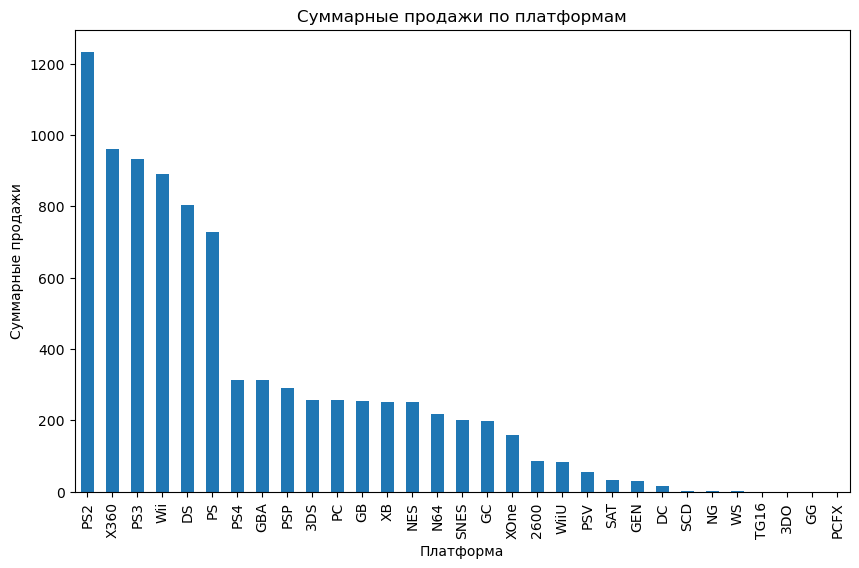

In [40]:
# Построение диаграммы для определения топа платформ по продажам
platform_sales.plot.bar(figsize=(10, 6))

# Настройки осей и заголовка диаграммы
plt.xlabel('Платформа')
plt.ylabel('Суммарные продажи')
plt.title('Суммарные продажи по платформам')

# Отображение диаграммы
plt.show()

Из графика выше видно, что шесть платформ наиболее ярко выделяются в сравнении с остальными. Платформой с наибольшими суммарными продажами за все время исследования является PS2 (более 1200 млн.).

In [41]:
# Выбор платформ с наибольшими суммарными продажами
top_platforms = platform_sales.head(6).index

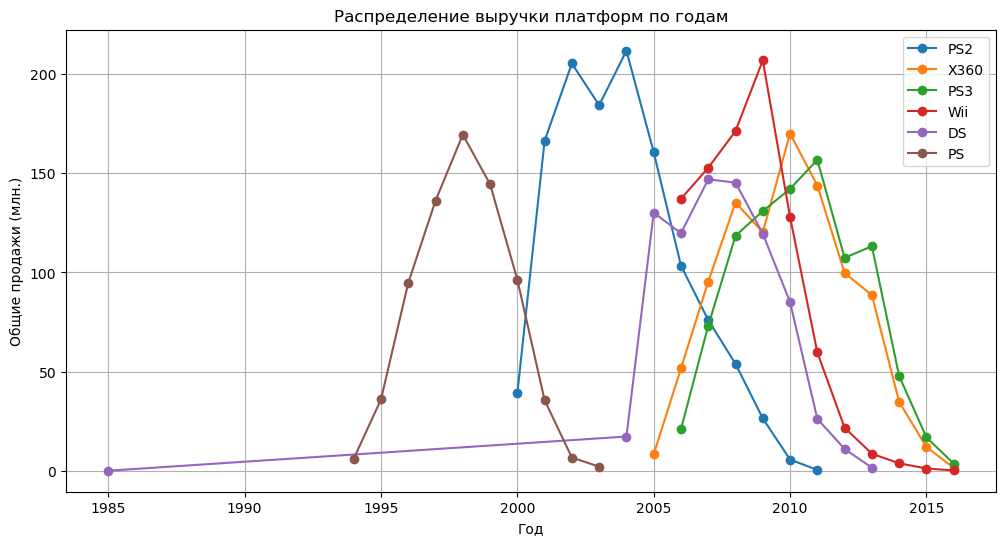

In [42]:
# Отбор данных только для выбранных платформ
top_platforms_data = games[(games['platform'].isin(top_platforms))]

# Построение распределения по годам для каждой платформы
fig, ax = plt.subplots(figsize=(12, 6))
for platform in top_platforms:
    platform_data = top_platforms_data[top_platforms_data['platform'] == platform]
    platform_data.groupby('year_of_release')['total_sales'].sum().plot(ax=ax, label=platform, marker='o')
    
# Настройка графика
plt.title('Распределение выручки платформ по годам')
plt.xlabel('Год')
plt.ylabel('Общие продажи (млн.)')
plt.legend()
plt.grid(True)

# Отображение графика
plt.show()

На графике выше отображено распределение дохода по каждой платформе по годам. Можно заметить, что платформа PS перестала приносить доход в 2003 году, PS2 в 2011, а DS в 2013. В то время как платформы Wii, X360 и PS3 появились и начали резко расти после 2005 года. У платформы Wii наблюдается резки спад в продажах после пика в 2009 году. В целом можно заметить тенденцию, что при падении продаж одной платформы, другая начинает расти. Особенно это заметно на линейке платформ PlayStation. 

Еще один интересный аспект, который можно заметить на графике - это то, что средний срок жизни одной платформы составляет примерно 10-11 лет. А также то, что новые платформы появлялись раньше каждые пять лет, однако в 2005-2006 появилось 3 новые платформы и с каждым годом количество активных игровых платформ только растет.

Также на графике подозрительно сильно выбивается DS, так как она одна берет начало в 1985 года, однако следующие данные появляются только в 2004. Я планирую рассмотреть это подробнее.

In [43]:
games.query('platform == "DS" & year_of_release < 2004')

,name,platform,year_of_release,genre,na_sales,eu_sales,jp_sales,other_sales,critic_score,user_score,rating,total_sales
15957,Strongest Tokyo University Shogi DS,DS,1985,Action,0.0,0.0,0.02,0.0,NaN,NaN,None,0.02


Как видно из запроса выше, есть всего одна игра на DS, которая была выпущена до 2004 года. Для чистоты анализа, я ее удалю.

In [44]:
games = games.query('platform != "DS" | year_of_release >= 2004')

После этого я еще раз построю график распределения выручки.

In [45]:
top_platforms_data = games[(games['platform'].isin(top_platforms))]

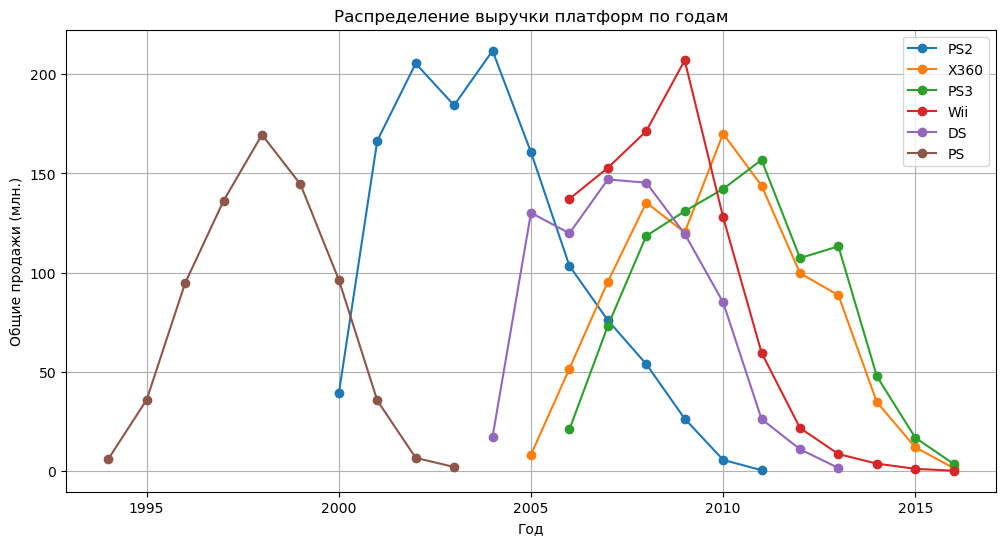

In [46]:
fig, ax = plt.subplots(figsize=(12, 6))
for platform in top_platforms:
    platform_data = top_platforms_data[top_platforms_data['platform'] == platform]
    platform_data.groupby('year_of_release')['total_sales'].sum().plot(ax=ax, label=platform, marker='o')
    
plt.title('Распределение выручки платформ по годам')
plt.xlabel('Год')
plt.ylabel('Общие продажи (млн.)')
plt.legend()
plt.grid(True)
plt.show()

Теперь из графика видно, что платформа DS появилась в 2004 году, а не раньше. Однако на другие выводы эти изменения никак не повлияли. 

<b>Взять данные за соответствующий **актуальный период.** Актуальный период определить самостоятельно в результате исследования предыдущих вопросов. Основной фактор — эти данные помогут построить прогноз на 2017 год.</b>

Учитывая данные, которые были получены ранее в анализе, я считаю, что за **актуальный период** стоит взять период с 2013 по 2016 год, так как после 2013 года появились платформы, которые актуальны до сих пор, а те платформы, которые приносили наибольший доход в предыдущие годы уже не являются продающими. Таким образом, мы сможем исключить их из анализа и сосредоточиться только на тех площадках, игры на которые выпускаются сейчас. 

<b>Какие платформы лидируют по продажам, растут или падают? Выбрать несколько потенциально прибыльных платформ.</b>

Для ответа на данный вопрос следует совершить следующие действия: 
- Отфильтровать данные по платформам с подсчитанными суммарными продажами для каждой платформы, взяв только данные с 2013 года и отсортировать их по убыванию суммарных продаж.
- Выбрать несколько платформ с наибольшими суммарными продажами.
- Проанализировать изменение продаж для выбранных платформ за каждый год этого периода. Построить график для визуализации изменений.

In [47]:
#Группировка данных по платформам, подсчет суммарных продаж и фильтр по году выпуска.
platform_sales_year_2013 = games[games['year_of_release'] >= 2013].groupby('platform')['total_sales'].sum().sort_values(ascending=False)

In [48]:
platform_sales_year_2013

platform
PS4     314.14
PS3     181.43
XOne    159.32
3DS     143.25
X360    136.80
WiiU     64.63
PC       39.43
PSV      32.99
Wii      13.66
PSP       3.50
DS        1.54
Name: total_sales, dtype: float64

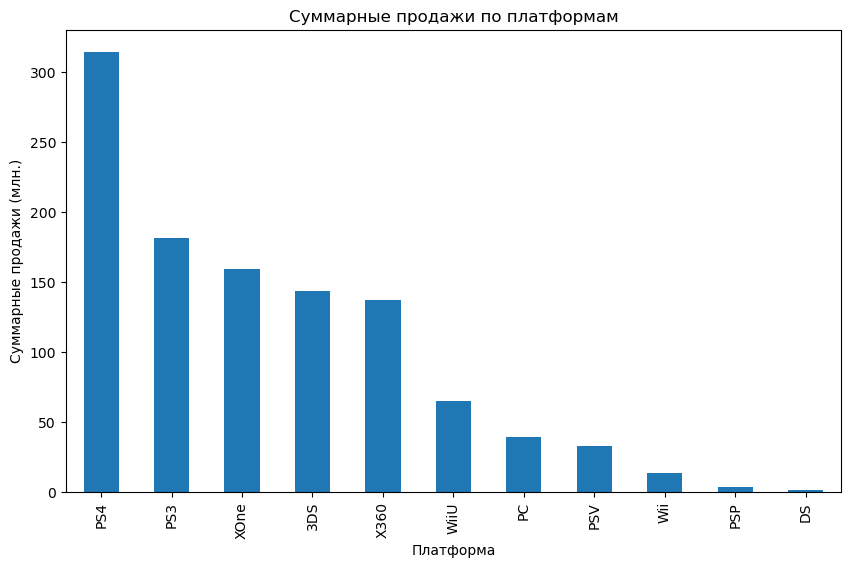

In [49]:
# Построение диаграммы для определения топа платформ по продажам
platform_sales_year_2013.plot.bar(figsize=(10, 6))

# Настройки осей и заголовка диаграммы
plt.xlabel('Платформа')
plt.ylabel('Суммарные продажи (млн.)')
plt.title('Суммарные продажи по платформам')

# Отображение диаграммы
plt.show()

На графике выше явным лидером по количеству продаж является платформа PS4. Также в топ-5 входят: PS3, XOne, 3DS, X360. Поскольку всего платформ относительно немного, стоит попробовать отобразить изменения по всем им на графике.

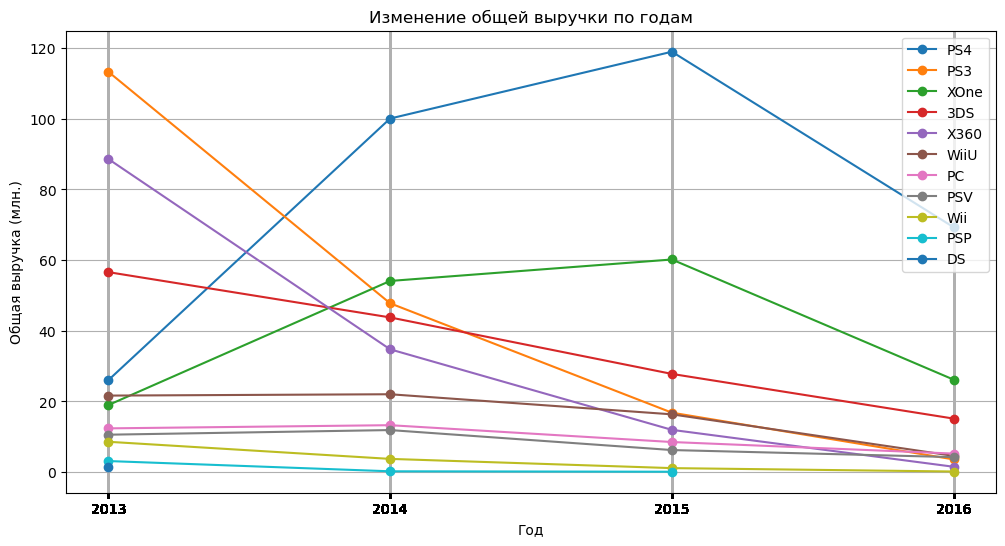

In [50]:
df_2013 = games.query("year_of_release >= 2013")
platforms = ['PS4', 'PS3', 'XOne', '3DS',  'X360', 'WiiU', 'PC', 'PSV', 'Wii', 'PSP', 'DS',]

plt.figure(figsize=(12, 6))

for platform in platforms:
    df_platform = df_2013[df_2013['platform'] == platform]
    sales_by_year = df_platform.groupby('year_of_release')['total_sales'].sum().reset_index()
    plt.plot(sales_by_year['year_of_release'], sales_by_year['total_sales'], label=platform,  marker='o')

plt.xlabel('Год')
plt.xticks(df_2013['year_of_release'])
plt.ylabel('Общая выручка (млн.)')
plt.title('Изменение общей выручки по годам')
plt.legend()
plt.grid(True)
plt.show()

Из графика можно увидеть, что платформы, которые являются наиболее перспективными это PS4 и XOne, хоть у них в настоящее время и наблюдается спад, но продажи все еще далеки от нуля, в отличии от других платформ. Конечно, стоит отметить, что платформа 3DS тоже все еще приносит доход, однако у нее наблюдается более линейный спад, в отличии от вышеупомянутых платформ. 

<b>Построить график «ящик с усами» по глобальным продажам игр в разбивке по платформам</b>

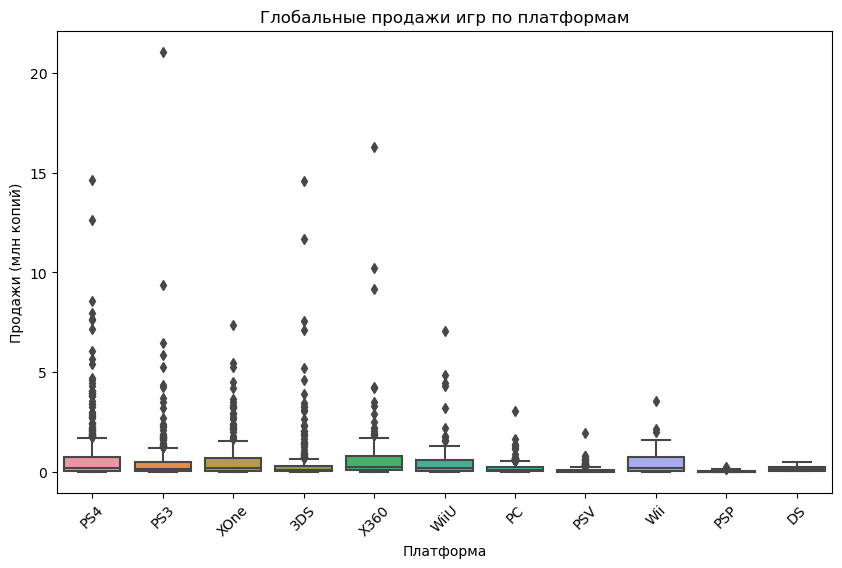

In [51]:
plt.figure(figsize=(10, 6))
sns.boxplot(x='platform', y='total_sales', data=df_2013, order=platform_sales_year_2013.index)
plt.xlabel('Платформа')
plt.ylabel('Продажи (млн копий)')
plt.title('Глобальные продажи игр по платформам')
plt.xticks(rotation=45)
plt.show()

Данный вид графика не дает какого-то четкого представления о распределении данных, так как большинство скопилось в нижней части графика. Посмотрю в целом распределение значении в колонке с общими продажами.

In [52]:
games['total_sales'].describe()

count    16442.000000
mean         0.536087
std          1.558870
min          0.000000
25%          0.060000
50%          0.170000
75%          0.470000
max         82.540000
Name: total_sales, dtype: float64

Из описания выше видно, что большинство значений действительно распределено в промежутке от 0 до 1. Построю еще один ящик с усами, но поближе рассмотрев именно этот интервал.

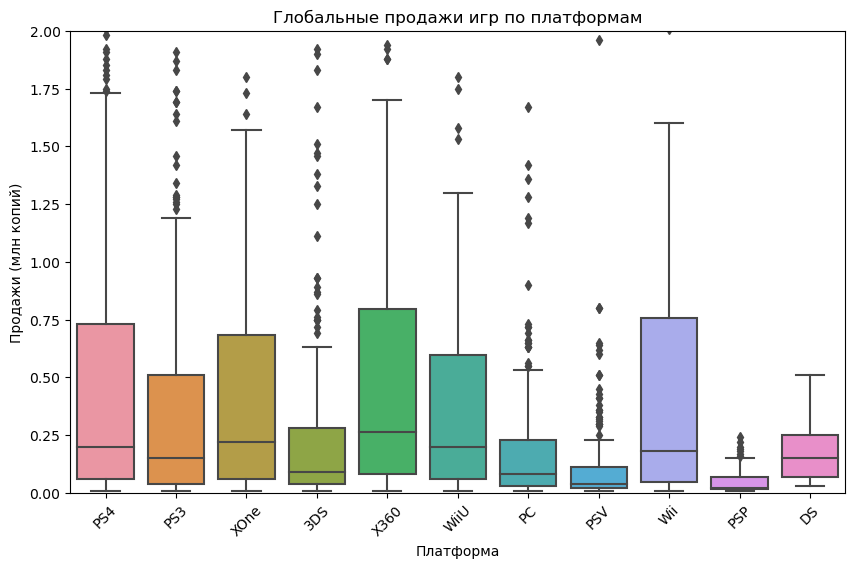

In [53]:
plt.figure(figsize=(10, 6))
sns.boxplot(x='platform', y='total_sales', data=df_2013, order=platform_sales_year_2013.index)
plt.xlabel('Платформа')
plt.ylabel('Продажи (млн копий)')
plt.title('Глобальные продажи игр по платформам')
plt.ylim(0, 2)
plt.xticks(rotation=45)
plt.show()

Из этого графика видно, что у всех платформ медиана находится в промежутке от 0 до 0.25, однако у всех платформ есть большое количество выбросов в верху ящика. Они могут быть обоснованы некоторыми очень успешными играми, возможно экслюзивами для тех или иных платформ.

<b>Посмотреть, как влияют на продажи внутри одной популярной платформы отзывы пользователей и критиков. Построить диаграмму рассеяния и посчитать корреляцию между отзывами и продажами.</b>

Для выполнения этого задания я решила взять за популярную платформу 'PS4', так как именно она является самой проадющей за последние годы. 

Чтобы выполнить данный анализ, я планирую выполнить следующие шаги:
- Выделить данные только для платформы 'PS4' из общего датасета games.
- Отфильтровать строки, где значения critic_score и user_score не являются NaN (то есть есть оценки от критиков и пользователей).
- Построить диаграмму рассеяния с отзывами пользователей и критиков и продажами.
- Посчитать корреляцию между отзывами пользователей и продажами.
- Посчитать корреляцию между отзывами критиков и продажами.
- Сформулировать выводы на основе полученных результатов.

In [54]:
# Выделить данные только для платформы 'PS4'
ps4_games = df_2013[df_2013['platform'] == 'PS4']

In [55]:
ps4_games.head()

,name,platform,year_of_release,genre,na_sales,eu_sales,jp_sales,other_sales,critic_score,user_score,rating,total_sales
31,Call of Duty: Black Ops 3,PS4,2015,Shooter,6.03,5.86,0.36,2.38,NaN,NaN,None,14.63
42,Grand Theft Auto V,PS4,2014,Action,3.96,6.31,0.38,1.97,97.0,8.3,M,12.62
77,FIFA 16,PS4,2015,Sports,1.12,6.12,0.06,1.28,82.0,4.3,E,8.58
87,Star Wars Battlefront (2015),PS4,2015,Shooter,2.99,3.49,0.22,1.28,NaN,NaN,None,7.98
92,Call of Duty: Advanced Warfare,PS4,2014,Shooter,2.81,3.48,0.14,1.23,83.0,5.7,M,7.66


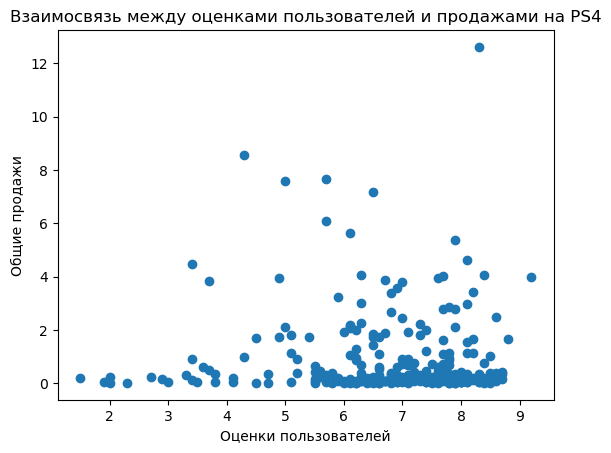

In [56]:
# Построить диаграмму рассеяния
plt.scatter(ps4_games['user_score'], ps4_games['total_sales'])
plt.xlabel('Оценки пользователей')
plt.ylabel('Общие продажи')
plt.title('Взаимосвязь между оценками пользователей и продажами на PS4')
plt.show()

На первый взгляд не заметно какой-то связи между оценками пользователей и общими продажами игр. 

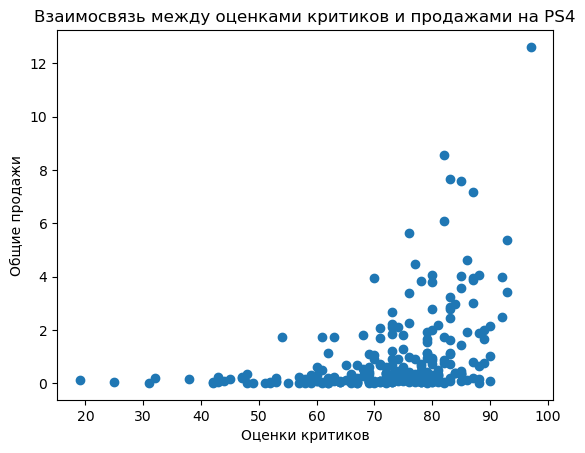

In [57]:
plt.scatter(ps4_games['critic_score'], ps4_games['total_sales'])
plt.xlabel('Оценки критиков')
plt.ylabel('Общие продажи')
plt.title('Взаимосвязь между оценками критиков и продажами на PS4')
plt.show()

Судя по графику присутствует небольшая связь между оценками критиков и общими продажами: чем выше оценка, тем больше продаж. Однако утверждать об этом нельзя, исходя только из диаграммы рассеяния. 

In [58]:
# Рассчитать корреляцию между отзывами пользователей и продажами
user_score_correlation = ps4_games['user_score'].corr(ps4_games['total_sales'])
print('Корреляция между оценками пользователей и общим объемом продаж на PS4:', user_score_correlation)

Корреляция между оценками пользователей и общим объемом продаж на PS4: -0.03195711020455644


В данном случае, близкое к нулю значение (-0.0319) указывает на то, что связь между оценками пользователей и объемом продаж слаба. 

Отрицательное значение означает, что в целом, с увеличением оценок пользователей, общий объем продаж склонен снижаться, и наоборот. Однако, влияние оценок на продажи не очень выражено, и другие факторы могут оказывать большее влияние на объем продаж товаров или услуг.

In [59]:
# Рассчитать корреляцию между отзывами критиков и продажами
critic_score_correlation = ps4_games['critic_score'].corr(ps4_games['total_sales'])
print('Корреляция между оценками критиков и общим объемом продаж на PS4:', critic_score_correlation)

Корреляция между оценками критиков и общим объемом продаж на PS4: 0.40656790206178123


В случае с оценками критиков, ситуация прямо противоположная, значение 0.4066 говорит о том, что с увеличением оценок критиков общий объем продаж также увеличивается, и наоборот. 

Однако, стоит отметить, что коэффициент корреляции не обязательно указывает на причинно-следственную связь между переменными. Другими словами, хотя оценки критиков и объем продаж могут быть связаны, это не обязательно означает, что высокие оценки критиков прямо приводят к большим объемам продаж; могут существовать и другие факторы, влияющие на эту связь.

Чтобы удостовериться в своих выводах напишу функцию и проверю корреляцию для других платформ.

In [60]:
def analyze_platform(platform_name, df):
    # Выделить данные только для указанной платформы
    platform_games = df[df['platform'] == platform_name]
    
    # Рассчитать корреляцию между отзывами пользователей и продажами
    user_score_correlation = platform_games['user_score'].corr(platform_games['total_sales'])
    
    # Рассчитать корреляцию между отзывами критиков и продажами
    critic_score_correlation = platform_games['critic_score'].corr(platform_games['total_sales'])
    
    # Построить диаграмму рассеяния для отзывов пользователей
    plt.scatter(platform_games['user_score'], platform_games['total_sales'])
    plt.xlabel('Оценки пользователей')
    plt.ylabel('Общие продажи')
    plt.title(f'Взаимосвязь между оценками пользователей и продажами на {platform_name}')
    plt.show()
    
    # Построить диаграмму рассеяния для отзывов критиков
    plt.scatter(platform_games['critic_score'], platform_games['total_sales'])
    plt.xlabel('Оценки критиков')
    plt.ylabel('Общие продажи')
    plt.title(f'Взаимосвязь между оценками критиков и продажами на {platform_name}')
    plt.show()
    
    return user_score_correlation, critic_score_correlation

Теперь проверим корреляцию на остальных платформах, которые входят в топ-5 продаж в актуальном периоде: PS3, XOne, 3DS, X360

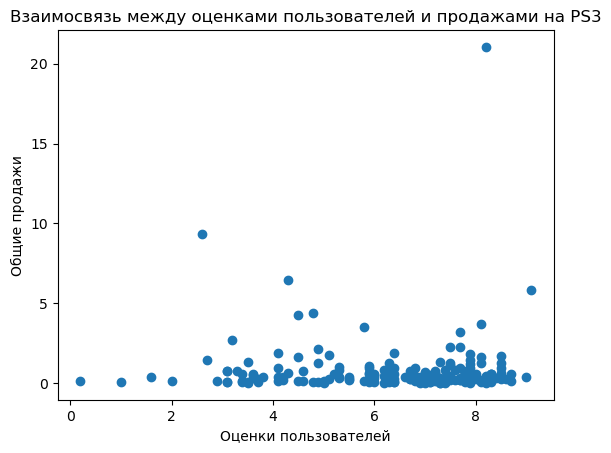

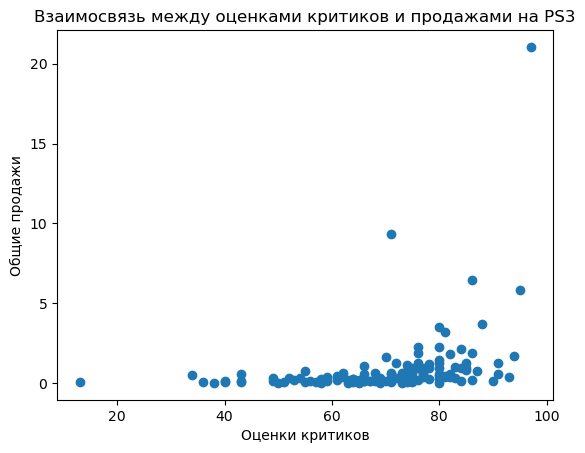

Корреляция между отзывами пользователей и продажами на PS3: 0.0023944027357567033
Корреляция между отзывами критиков и продажами на PS3: 0.33428533933719184


In [61]:
ps3_user_corr, ps3_critic_corr = analyze_platform('PS3', df_2013)
print(f'Корреляция между отзывами пользователей и продажами на PS3: {ps3_user_corr}')
print(f'Корреляция между отзывами критиков и продажами на PS3: {ps3_critic_corr}')

Корреляция между отзывами пользователей и продажами на PS3 составляет всего 0.0024, что практически отсутствие корреляции. Это означает, что оценки пользователей на PS3 не оказывают существенного влияния на объем продаж.

Корреляция между отзывами критиков и продажами на PS3 равна 0.3343, что может указывать на умеренную положительную корреляцию между оценками критиков и продажами на этой платформе. Это может означать, что более высокие оценки критиков связаны с более высокими продажами на PS3.

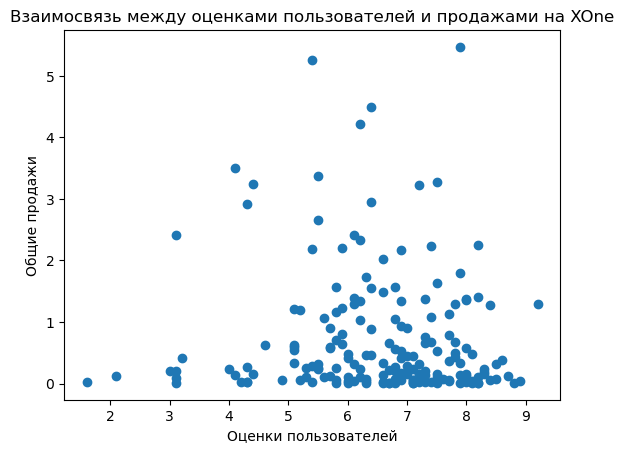

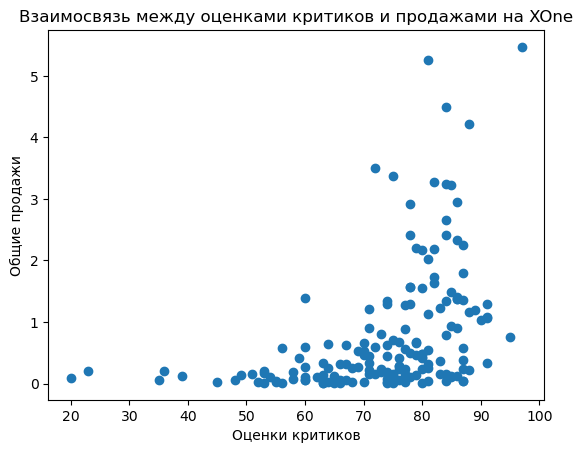

Корреляция между отзывами пользователей и продажами на XOne: -0.06892505328279418
Корреляция между отзывами критиков и продажами на XOne: 0.41699832800840153


In [62]:
xone_user_corr, xone_critic_corr = analyze_platform('XOne', df_2013)
print(f'Корреляция между отзывами пользователей и продажами на XOne: {xone_user_corr}')
print(f'Корреляция между отзывами критиков и продажами на XOne: {xone_critic_corr}')

Для XOne корреляция между отзывами пользователей и продажами составляет -0.0689, что говорит о слабой отрицательной корреляции. Это может указывать на то, что выше оцененные пользователями игры на XOne могут иметь ниже продажи. Однако корреляция не слишком сильная.

Корреляция между отзывами критиков и продажами на XOne равна 0.4170, что указывает на умеренную положительную связь между оценками критиков и продажами на данной платформе. Высокие оценки критиков могут сказываться на увеличении продаж.

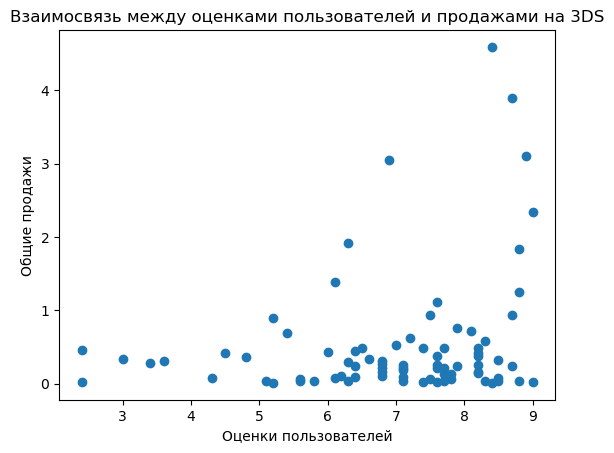

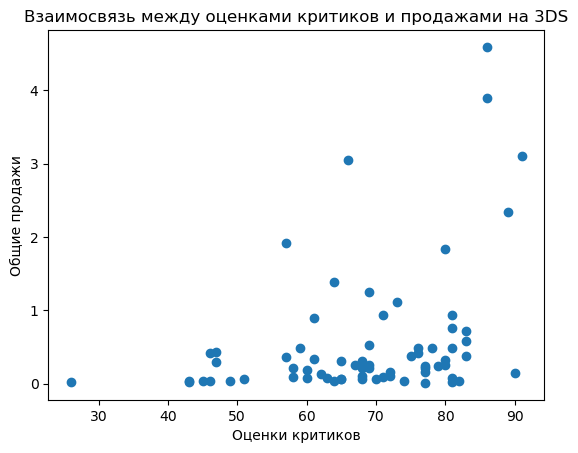

Корреляция между отзывами пользователей и продажами на 3DS: 0.24150411773563005
Корреляция между отзывами критиков и продажами на 3DS: 0.3570566142288104


In [63]:
ds3_user_corr, ds3_critic_corr = analyze_platform('3DS', df_2013)
print(f'Корреляция между отзывами пользователей и продажами на 3DS: {ds3_user_corr}')
print(f'Корреляция между отзывами критиков и продажами на 3DS: {ds3_critic_corr}')

Для 3DS корреляция между отзывами пользователей и продажами составляет 0.2415, что говорит о некоторой положительной корреляции. Это может означать, что игры с более высокими оценками пользователей на 3DS имеют немного больший объем продаж.

Корреляция между отзывами критиков и продажами на 3DS равна 0.3571, что также указывает на умеренную положительную корреляцию. Это означает, что оценки критиков могут оказывать некоторое влияние на продажи игр на 3DS.

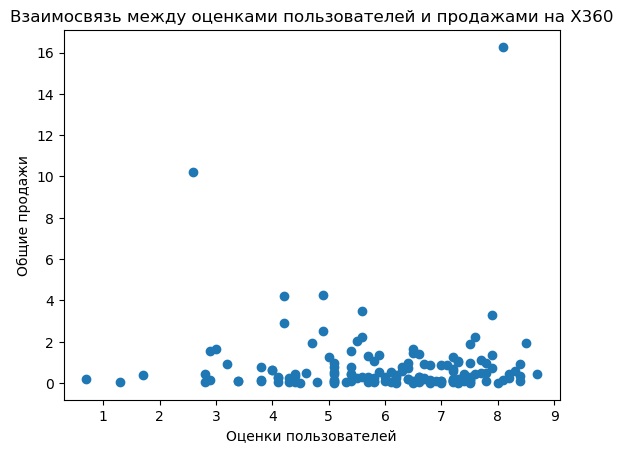

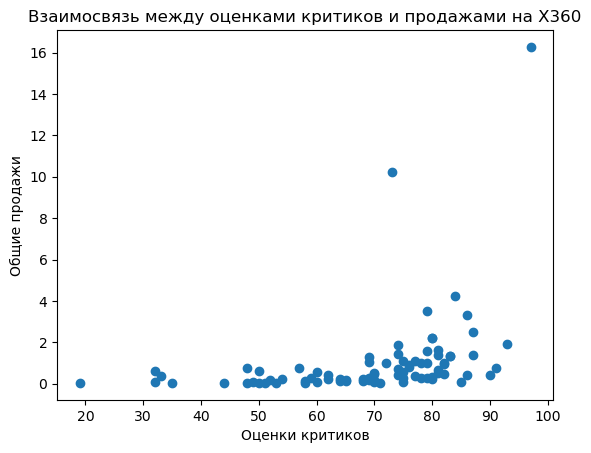

Корреляция между отзывами пользователей и продажами на X360: -0.011742185147181334
Корреляция между отзывами критиков и продажами на X360: 0.35034454602286647


In [64]:
x360_user_corr, x360_critic_corr = analyze_platform('X360', df_2013)
print(f'Корреляция между отзывами пользователей и продажами на X360: {x360_user_corr}')
print(f'Корреляция между отзывами критиков и продажами на X360: {x360_critic_corr}')

Для X360 корреляция между отзывами пользователей и продажами равна -0.0117, что говорит о практически отсутствии корреляции. Оценки пользователей на X360 не имеют существенного влияния на продажи.

Корреляция между отзывами критиков и продажами на X360 составляет 0.3503, что указывает на умеренную положительную корреляцию. Это может означать, что более высокие оценки критиков связаны с более высокими продажами на X360.

**Общий вывод:**
Оценки критиков, в большинстве случаев, имеют более существенное влияние на продажи игр, чем оценки пользователей. Однако корреляция не всегда является сильной, и другие факторы также могут влиять на успех игр на разных платформах.

<b>Посмотреть на общее распределение игр по жанрам. Что можно сказать о самых прибыльных жанрах? Выделяются ли жанры с высокими и низкими продажами?</b>

In [65]:
# Группировка данных по жанрам и подсчет медианы продаж
genre_sales = df_2013.groupby('genre')['total_sales'].median().sort_values(ascending=False)

Было решено посмотреть не сумму продаж по жанрам, а медиану, так как она менее подвержена выбросам.

In [66]:
genre_sales 

genre
Shooter         0.450
Sports          0.240
Platform        0.225
Role-Playing    0.125
Fighting        0.125
Racing          0.120
Action          0.110
Simulation      0.100
Misc            0.100
Strategy        0.080
Puzzle          0.060
Adventure       0.030
Name: total_sales, dtype: float64

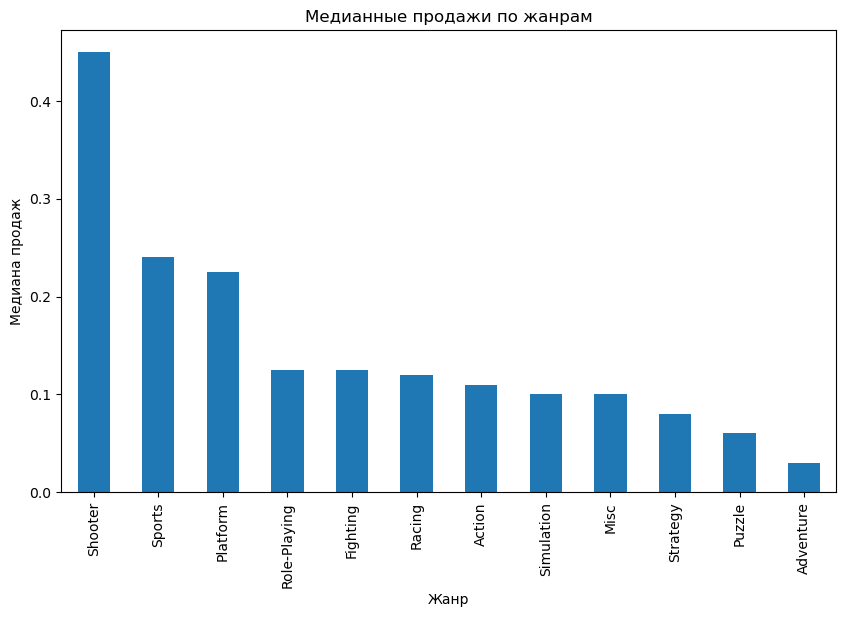

In [67]:
# Построение диаграммы для определения топа жанров по продажам
genre_sales.plot.bar(figsize=(10, 6))
plt.xlabel('Жанр')
plt.ylabel('Медиана продаж')
plt.title('Медианные продажи по жанрам')
plt.show()

Из графика выше можно заметить, что наиболее прибыльным жанром является жанр "Shooter", он принесит в среднем около 0.450 миллионов. В то время как наименее прибыльным жанром является жанр приключений, который принес примерно 0.030 миллионов.

**Шаг 4. Составить портрет пользователя каждого региона**

Определить для пользователя каждого региона (*NA, EU, JP*):

- Самые популярные платформы (топ-5). Опишите различия в долях продаж.
- Самые популярные жанры (топ-5). Поясните разницу.
- Влияет ли рейтинг ESRB на продажи в отдельном регионе?

In [68]:
platform_sales_na = df_2013.groupby('platform')['na_sales'].sum().sort_values(ascending=False)
platform_sales_na

platform
PS4     108.74
XOne     93.12
X360     81.66
PS3      63.50
3DS      38.20
WiiU     29.21
PC       11.11
Wii       6.56
PSV       5.04
DS        0.57
PSP       0.00
Name: na_sales, dtype: float64

In [69]:
top_platforms_na = platform_sales_na.head(5)
top_platforms_na

platform
PS4     108.74
XOne     93.12
X360     81.66
PS3      63.50
3DS      38.20
Name: na_sales, dtype: float64

In [70]:
# Объединение остальных платформ в отдельную категорию
other_platforms_na = platform_sales_na[5:].sum()
other_platforms_na

52.49

Теперь надо добавить объединенные остальные платформы в топ-5.

In [71]:
# Создаем новую переменную platform_sales_combined_na и копируем туда датафрейм с топ-5 платформами
platform_sales_combined_na = top_platforms_na.copy()

# Добавляем новое значение из other_platforms_na
platform_sales_combined_na["Другие"] = other_platforms_na 

In [72]:
platform_sales_combined_na

platform
PS4       108.74
XOne       93.12
X360       81.66
PS3        63.50
3DS        38.20
Другие     52.49
Name: na_sales, dtype: float64

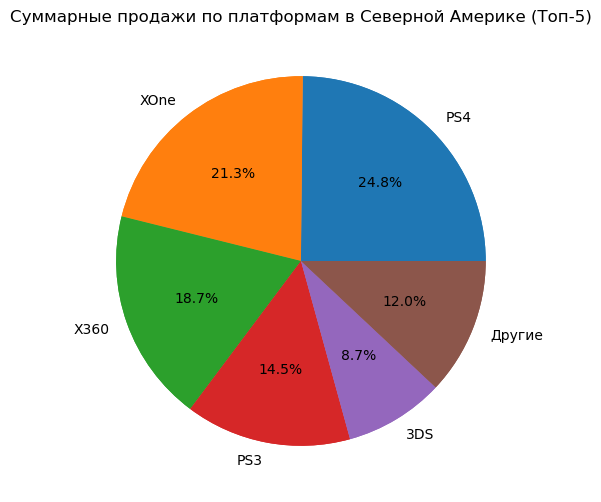

In [73]:
# Построение диаграммы для определения топа платформ по продажам
platform_sales_combined_na.plot.pie(figsize=(10, 6))

# Настройки осей и заголовка диаграммы
plt.xlabel('')
plt.ylabel('')
plt.title('Суммарные продажи по платформам в Северной Америке (Топ-5)')
plt.pie(platform_sales_combined_na, autopct='%1.1f%%')

# Отображение диаграммы
plt.show()

Исходя из данных выше наиболее популярными платформами в Северной Америке являются PlayStation 4, Xbox One, Xbox 360, PlayStation 3 и Nintendo 3DS. Из них лидером является PlayStation 4 с общими продажами в размере 108.74 миллиона, однако Xbox One также занимает большую долю с 93.12 миллионами суммарных продаж. 

In [74]:
genre_sales_na = df_2013.groupby('genre')['na_sales'].sum().sort_values(ascending=False)
genre_sales_na

genre
Action          126.05
Shooter         109.74
Sports           65.27
Role-Playing     46.40
Misc             27.49
Platform         18.14
Fighting         15.55
Racing           12.96
Adventure         7.14
Simulation        4.86
Strategy          3.28
Puzzle            0.83
Name: na_sales, dtype: float64

In [75]:
# Получаем топ-5 жанров по продажам в Северной Америке
top_genres_na = genre_sales_na.head(5)

# Суммируем продажи остальных жанров
other_genres_na = genre_sales_na[5:].sum()

# Создаем новую переменную genre_sales_combined_na
genre_sales_combined_na = top_genres_na.copy()

# Добавляем новое значение "Другие" из other_genres_na
genre_sales_combined_na["Другие"] = other_genres_na

In [76]:
genre_sales_combined_na

genre
Action          126.05
Shooter         109.74
Sports           65.27
Role-Playing     46.40
Misc             27.49
Другие           62.76
Name: na_sales, dtype: float64

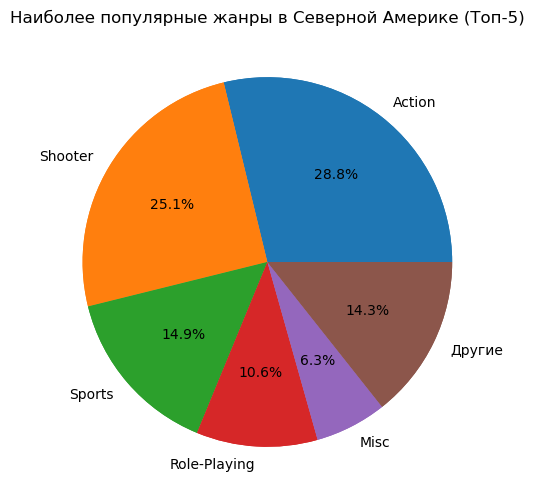

In [77]:
# Построение диаграммы для определения топа платформ по продажам
genre_sales_combined_na.plot.pie(figsize=(10, 6))

# Настройки осей и заголовка диаграммы
plt.xlabel('')
plt.ylabel('')
plt.title('Наиболее популярные жанры в Северной Америке (Топ-5)')
plt.pie(genre_sales_combined_na, autopct='%1.1f%%')

# Отображение диаграммы
plt.show()

Говоря про жанры, то здесь в топе для жителей Северной Америки являются жанр экшен и шутеры с 126.05 и 109.74 миллионами продаж соответственно. Также в топ входят спортивные и ролевые игры.

In [78]:
esrb_sales_na = df_2013.groupby('rating')['na_sales'].sum().sort_values(ascending=False)
esrb_sales_na

rating
M       165.21
None     89.42
E        79.05
E10+     54.24
T        49.79
Name: na_sales, dtype: float64

Наиболее продающий рейтинг игр в Северной Америке - «Для взрослых». После него идут игры с рейтингом для всех и для всех, старше 10.

In [79]:
platform_sales_eu = df_2013.groupby('platform')['eu_sales'].sum().sort_values(ascending=False)
platform_sales_eu.head()

platform
PS4     141.09
PS3      67.81
XOne     51.59
X360     42.52
3DS      30.96
Name: eu_sales, dtype: float64

In [80]:
top_platforms_eu = platform_sales_eu.head(5)
other_platforms_eu = platform_sales_eu[5:].sum()
platform_sales_combined_eu = top_platforms_eu.copy()
platform_sales_combined_eu["Другие"] = other_platforms_eu
platform_sales_combined_eu

platform
PS4       141.09
PS3        67.81
XOne       51.59
X360       42.52
3DS        30.96
Другие     58.26
Name: eu_sales, dtype: float64

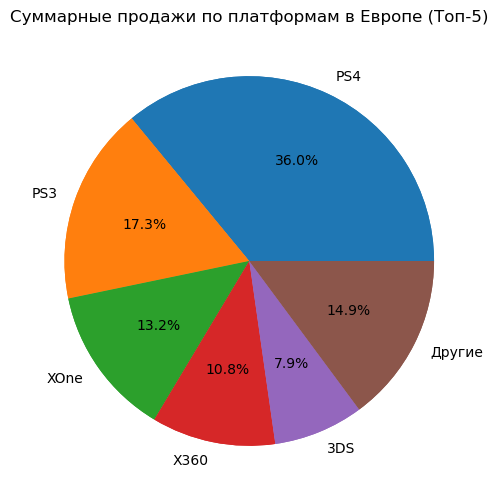

In [81]:
# Построение диаграммы для определения топа платформ по продажам
platform_sales_combined_eu.plot.pie(figsize=(10, 6))

# Настройки осей и заголовка диаграммы
plt.xlabel('')
plt.ylabel('')
plt.title('Суммарные продажи по платформам в Европе (Топ-5)')
plt.pie(platform_sales_combined_eu, autopct='%1.1f%%')

# Отображение диаграммы
plt.show()

В Европе наиболее популярной платформой является PlayStation 4 (141.09 млн.), она занимает 36% от всех продаж. Также в топ-5 входят: PlayStation 3, Xbox One, Xbox 360 и Nintendo 3DS.

In [82]:
genre_sales_eu = df_2013.groupby('genre')['eu_sales'].sum().sort_values(ascending=False)
genre_sales_eu

genre
Action          118.13
Shooter          87.86
Sports           60.52
Role-Playing     36.97
Racing           20.19
Misc             20.04
Platform         15.58
Simulation       10.92
Fighting          8.55
Adventure         8.25
Strategy          4.22
Puzzle            1.00
Name: eu_sales, dtype: float64

In [83]:
top_genres_eu = genre_sales_eu.head(5)
other_genres_eu = genre_sales_eu[5:].sum()
genre_sales_combined_eu = top_genres_eu.copy()
genre_sales_combined_eu["Другие"] = other_genres_eu
genre_sales_combined_eu

genre
Action          118.13
Shooter          87.86
Sports           60.52
Role-Playing     36.97
Racing           20.19
Другие           68.56
Name: eu_sales, dtype: float64

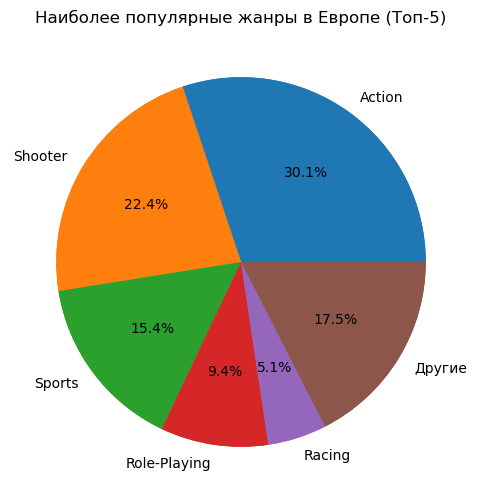

In [84]:
# Построение диаграммы для определения топа платформ по продажам
genre_sales_combined_eu.plot.pie(figsize=(10, 6))

# Настройки осей и заголовка диаграммы
plt.xlabel('')
plt.ylabel('')
plt.title('Наиболее популярные жанры в Европе (Топ-5)')
plt.pie(genre_sales_combined_eu, autopct='%1.1f%%')

# Отображение диаграммы
plt.show()

Касательно жанров игр, то здесь на первом месте также экшен игры, которые занимают 30.1 процент от всех жанров. На втором месте также шутеры. После этого идут спортивные, ролевые и гоночные игры. 

In [85]:
esrb_sales_eu = df_2013.groupby('rating')['eu_sales'].sum().sort_values(ascending=False)
esrb_sales_eu

rating
M       145.32
E        83.36
None     78.91
E10+     42.69
T        41.95
Name: eu_sales, dtype: float64

Распределение продаж по рейтингам схоже с распределением в Северной Америке, так как здесь также на первом месте стоит рейтинг «М» — «Для взрослых». На втором месте стоят игры для всех, а потом для всех старше 10. 

In [86]:
platform_sales_jp = df_2013.groupby('platform')['jp_sales'].sum().sort_values(ascending=False)
platform_sales_jp

platform
3DS     67.81
PS3     23.35
PSV     18.59
PS4     15.96
WiiU    10.88
PSP      3.29
X360     0.51
XOne     0.34
Wii      0.05
DS       0.00
PC       0.00
Name: jp_sales, dtype: float64

In [87]:
top_platforms_jp = platform_sales_jp.head(5)
other_platforms_jp = platform_sales_jp[5:].sum()
platform_sales_combined_jp = top_platforms_jp.copy()
platform_sales_combined_jp["Другие"] = other_platforms_jp
platform_sales_combined_jp

platform
3DS       67.81
PS3       23.35
PSV       18.59
PS4       15.96
WiiU      10.88
Другие     4.19
Name: jp_sales, dtype: float64

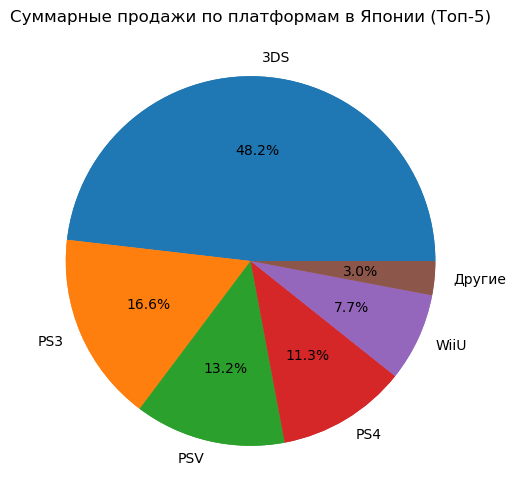

In [88]:
# Построение диаграммы для определения топа платформ по продажам
platform_sales_combined_jp.plot.pie(figsize=(10, 6))

# Настройки осей и заголовка диаграммы
plt.xlabel('')
plt.ylabel('')
plt.title('Суммарные продажи по платформам в Японии (Топ-5)')
plt.pie(platform_sales_combined_jp, autopct='%1.1f%%')

# Отображение диаграммы
plt.show()

В Японии наиболее популярной платформой является Nintendo 3DS (48.2%). Также в топ-5 входят: PlayStation 3 (16.6%), PlayStation Vita (13.2%), PlayStation 4 (11.3 %) и Wii U (7.7%).

In [89]:
genre_sales_jp = df_2013.groupby('genre')['jp_sales'].sum().sort_values(ascending=False)
genre_sales_jp.head()

genre
Role-Playing    51.04
Action          40.49
Misc             9.20
Fighting         7.65
Shooter          6.61
Name: jp_sales, dtype: float64

In [90]:
top_genres_jp = genre_sales_jp.head(5)
other_genres_jp = genre_sales_jp[5:].sum()
genre_sales_combined_jp = top_genres_jp.copy()
genre_sales_combined_jp["Другие"] = other_genres_jp
genre_sales_combined_jp

genre
Role-Playing    51.04
Action          40.49
Misc             9.20
Fighting         7.65
Shooter          6.61
Другие          25.79
Name: jp_sales, dtype: float64

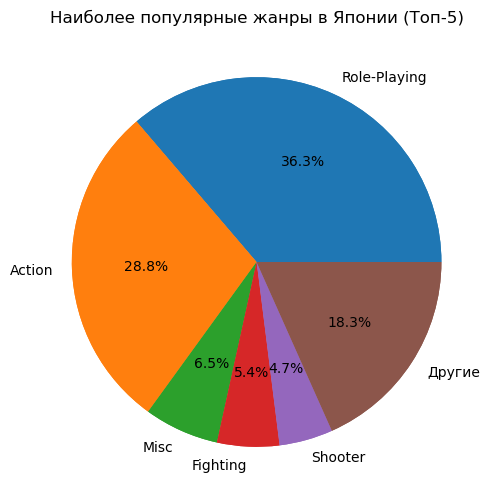

In [91]:
# Построение диаграммы для определения топа платформ по продажам
genre_sales_combined_jp.plot.pie(figsize=(10, 6))

# Настройки осей и заголовка диаграммы
plt.xlabel('')
plt.ylabel('')
plt.title('Наиболее популярные жанры в Японии (Топ-5)')
plt.pie(genre_sales_combined_jp, autopct='%1.1f%%')

# Отображение диаграммы
plt.show()

Говоря о жанрах, то явным лидером в Японии является жанр компьютерных ролевых игр. Он занимает 36.3% продаж. Также в топ входят экшен игры, файтинги и шутеры.

In [92]:
esrb_sales_jp = df_2013.groupby('rating')['jp_sales'].sum().sort_values(ascending=False)
esrb_sales_jp

rating
None    85.05
T       20.59
E       15.14
M       14.11
E10+     5.89
Name: jp_sales, dtype: float64

Распределение рейтингов игр в Японии отличается от Северной Америки и Европы. Здесь на первом месте стоит рейтинг "для подростков", потом "для всех", а потом "для взрослых".

In [93]:
esrb_sales = df_2013.pivot_table(index='rating', values=['na_sales', 'eu_sales', 'jp_sales'], aggfunc='sum')
esrb_sales = esrb_sales.rename(columns={'na_sales': 'Продажи Америка', 'eu_sales': 'Продажи Европа', 'jp_sales': 'Продажи Япония'})
esrb_sales = esrb_sales.sort_values(by=esrb_sales.columns[1], ascending=False)
esrb_sales

,Продажи Европа,Продажи Япония,Продажи Америка
rating,,,
None,78.91,85.05,89.42
T,41.95,20.59,49.79
E,83.36,15.14,79.05
M,145.32,14.11,165.21
E10+,42.69,5.89,54.24


Также я создала сводную таблицу по рейтингам игр и их уровне продаж для каждого региона. Как можно заметить, продажи в Европе и Америке очень схожи друг с другом, однако Япония практически прямо противоположна им по своим предпочтениям.

**Шаг 5. Проверить гипотезы**

- Средние пользовательские рейтинги платформ *Xbox One* и *PC* одинаковые;
- Средние пользовательские рейтинги жанров *Action* (англ. «действие», экшен-игры) и *Sports* (англ. «спортивные соревнования») разные.

**Средние пользовательские рейтинги платформ Xbox One и PC одинаковые;**

Нулевая гипотеза (H0): Средние пользовательские рейтинги платформ Xbox One и PC одинаковы.
<br>Альтернативная гипотеза (H1): Средние пользовательские рейтинги платформ Xbox One и PC различаются.

Данная формулировка гипотез основывается на том, что я хочу проверить статистические различия между средними пользовательскими рейтингами двух платформ - Xbox One и PC. Формулировка гипотез объясняется следующим образом:

В нулевой гипотезе предполагается, что нет статистически значимых различий между средними пользовательскими рейтингами Xbox One и PC. Это является стартовой позицией и тем, что я попытаюсь опровергнуть с помощью статистического анализа.

Альтернативная гипотеза предполагает, что существуют статистически значимые различия между средними пользовательскими рейтингами Xbox One и PC. Если данные обеспечат достаточные доказательства против нулевой гипотезы, я смогу отклонить нулевую гипотезу в пользу альтернативной. Выбор альтернативной гипотезы обусловлен необходимостью выявить существуют ли различия между рейтингами двух платформ. 

In [94]:
#Фильтрация игр, где 'platform' равно 'XOne'
xbox_one_games = df_2013[df_2013['platform'] == 'XOne'].dropna()

#Расчет среднего значения 'user_score' для игр на платформе Xbox One
xbox_one_user_score_mean = xbox_one_games['user_score'].mean()

print('Средний пользовательский рейтинг игр на платформе Xbox One:', xbox_one_user_score_mean)

Средний пользовательский рейтинг игр на платформе Xbox One: 6.538181818181818


In [95]:
#Фильтрация игр, где 'platform' равно 'PC'
pc_games = df_2013[df_2013['platform'] == 'PC'].dropna()

#Расчет среднего значения 'user_score' для игр на платформе PC
pc_user_score_mean = pc_games['user_score'].mean()

print('Средний пользовательский рейтинг игр на платформе PC:', pc_user_score_mean)

Средний пользовательский рейтинг игр на платформе PC: 6.3020270270270276


In [96]:
#Проверка гипотезы с помощью t-теста

alpha = 0.05 #уровень статистической значимости 

results = st.ttest_ind(xbox_one_games['user_score'], pc_games['user_score'], equal_var=False)

print('p-значение:', results.pvalue)

if results.pvalue < alpha: # сравните получившееся p-значение с alpha
    print('Отвергаем нулевую гипотезу: Средние пользовательские рейтинги платформ Xbox One и PC различаются.')
else:
    print('Не отвергаем нулевую гипотезу: Средние пользовательские рейтинги платформ Xbox One и PC одинаковы.')

p-значение: 0.17882648263401307
Не отвергаем нулевую гипотезу: Средние пользовательские рейтинги платформ Xbox One и PC одинаковы.


**Средние пользовательские рейтинги жанров Action (англ. «действие», экшен-игры) и Sports (англ. «спортивные соревнования») разные.**

Нулевая гипотеза (H0): Средние пользовательские рейтинги жанров Action и Sports одинаковы.
<br>Альтернативная гипотеза (H1): Средние пользовательские рейтинги жанров Action и Sports различаются.

Формулировка гипотез в данном случае также основывается на желании выявить статистические различия между двумя значениями: средними пользовательскими рейтингами двух жанров игр - Action и Sports. Вот как были сформулированы гипотезы:

В нулевой гипотезе предполагается, что нет статистически значимых различий между средними пользовательскими рейтингами жанров Action и Sports. Это исходное предположение, которое я попытаюсь опровергнуть с помощью статистического анализа.

Альтернативная гипотеза предполагает, что существуют статистически значимые различия между средними пользовательскими рейтингами жанров Action и Sports. Если данные обеспечат достаточные доказательства против нулевой гипотезы, я смогу отклонить ее в пользу альтернативной. Выбор такой альтернативной гипотезы обусловлен желанием выяснить, существуют ли различия между средними пользовательскими рейтингами двух жанров игр. 

In [97]:
#Фильтрация игр, где жанр'Action'
action_games = df_2013[df_2013['genre'] == 'Action'].dropna()

#Расчет среднего значения 'user_score' для игр в жанре 'Action'
action_user_score_mean = action_games['user_score'].mean()

print('Средний пользовательский рейтинг экшен-игр', action_user_score_mean)

Средний пользовательский рейтинг экшен-игр 6.9362459546925574


In [98]:
#Фильтрация игр, где жанр'Sports'
sports_games = df_2013[df_2013['genre'] == 'Sports'].dropna()

#Расчет среднего значения 'user_score' для игр в жанре 'Sports'
sports_user_score_mean = sports_games['user_score'].mean()

print('Средний пользовательский рейтинг спортивных игр', sports_user_score_mean)

Средний пользовательский рейтинг спортивных игр 5.665454545454545


In [99]:
#Проверка гипотезы с помощью t-теста

alpha = 0.05 

results = st.ttest_ind(action_games['user_score'], sports_games['user_score'], equal_var=True)

print('p-значение:', results.pvalue)

if results.pvalue < alpha: # сравните получившееся p-значение с alpha
    print('Отвергаем нулевую гипотезу: Средние пользовательские рейтинги жанров Action и Sports различаются.')
else:
    print('Не отвергаем нулевую гипотезу: Средние пользовательские рейтинги жанров Action и Sports одинаковы.')

p-значение: 1.684099430689953e-16
Отвергаем нулевую гипотезу: Средние пользовательские рейтинги жанров Action и Sports различаются.


Для проверки обеих гипотез использовался метод для проверки гипотезы о равенстве среднего двух генеральных совокупностей по взятым из них выборкам: scipy.stats.ttest_ind(array1, array2, equal_var, alternative).

Этот метод подходит так как:
1. Выборки независимы друг от друга.
2. Выборочные средние нормально распределены. 
3. Хоть размер выборок отличается в первом случае, это было учтенно в параметре equal_var. 
4. Выборки представляют собой числовые данные, и я хотела сравнить их средние значения.

**Шаг 6. Общий вывод**

После выгрузки и первичного осмотра данных, передо мной стояло несколько задач, которые надо было выполнить прежде чем приступить к полноценному анализу данных.

1. **Подготовка данных**

Для начала надо было привести все названия столбцов к нижнему регистру и корректному типу данных. 

Столбец "year_of_release" был преобразован в тип данных int, так как год выпуска представлен только целыми числами. 

Столбец user_score был изменен на float, так как оценка пользователя - числовое значение, не строка, как изначально указано. Значения tbd в этом столбце были заменены на nan, поскольку они означают "to be determined", т.е. отсутствие оценки.

Проверены столбцы на пропуски. В столбце name обнаружены два пропуска, информации об этих играх практически не было, поэтому они удалены. В столбце с оценкой критиков и пользователей оставлены 8576 и 9123 пропуска соответственно, так как невозможно восстановить данные. 

В столбце year_of_release также были пропуски, их было решено удалить. Причиной их могли быть технические ошибки или отсутствие точных данных о дате публикации некоторых игр в открытых источниках.

В колонке с рейтингом отсутствуют значения у 6764 строк. Пропуски заменила на значение None, чтобы оно также отображалось в статистике..

Просмотрев все столбцы на наличие дубликатов и убрав один неявный дубликат, я добавила новый столбец, где суммировала общие продажи каждой игры. 

2. **Исследовательский анализ данных**

Сначала я изучала распределение игр по годам выпуска, чтобы определить период, подходящий для дальнейшего анализа. Пик выпуска игр пришелся на 2008 и 2009 годы, после чего их количество снизилось. 

Наиболее активный период выпуска игр наступил после 1995 года, и даже количество игр, выпущенных с 1995 по 2000, значительно меньше, чем после этого времени.

Затем я рассмотрела изменения продаж по платформам. Из исследования стало ясно, что шесть платформ выделяются по продажам. PS2 оказалась лидером с общими продажами более 1200 миллионов. 

Распределение дохода по годам для каждой платформы показало, что PS прекратила приносить доход в 2003 году, PS2 в 2011, а DS в 2013. В то время как Wii, X360 и PS3 начали расти после 2005 года. Wii достигла пика в 2009 году, затем продажи резко упали. В общем можно отметить тенденцию: при падении продаж одной платформы, другая начинает расти, особенно в линейке PlayStation.

Еще один интересный аспект, который можно заметить - это то, что средний срок жизни одной платформы составляет примерно 10-11 лет. А также то, что новые платформы появлялись раньше каждые пять лет, однако в 2005-2006 появилось 3 новые платформы и с каждым годом количество активных игровых платформ только растет.

Учитывая предварительные данные, я предполагаю, что актуальным периодом будет 2013-2016 года, так как после 2013 года появились актуальные платформы, а более ранние лидеры по продажам уже устарели. Таким образом, мы можем исключить их из анализа и сосредоточиться на платформах, которые актуальны в настоящее время.

Затем я исследовала лидеров продаж, их рост или спад в актуальном периоде. На графике выше явным лидером по количеству продаж является платформа PS4. Также в топ-5 входят: PS3, XOne, 3DS, X360. Поскольку всего платформ относительно немного, стоит попробовать отобразить изменения по всем им на графике.

Исходя из исследования, можно сделать вывод, что перспективными платформами являются PS4 и XOne, несмотря на снижение продаж, они все еще далеки от нуля, в отличие от других платформ. Платформа 3DS также приносит доход, но с более линейным спадом.

Также было проведено исследование влияния отзывов пользователей и критиков на продажи:
<br>Результаты анализа показали, что оценки критиков, в большинстве случаев, имеют более существенное влияние на продажи игр, чем оценки пользователей. Однако корреляция не всегда является сильной, и другие факторы также могут влиять на успех игр на разных платформах.

Завершая исследовательский анализ, я рассмотрела распределение выручки по жанрам. Таким образом оказалось, что наиболее прибыльным жанром является жанр "Shooter", он приносит в среднем около 0.45 миллионов. В то время как наименее прибыльным жанром является жанр приключений, который принес примерно 0.03 миллионов.

3. **Портрет пользователя каждого региона**

Обобщая данные по портрету пользователя каждого региона, можно выделить несколько ключевых тенденций:

**Северная Америка:**

- PlayStation 4 и Xbox One являются лидирующими платформами, с PlayStation 4 на первом месте.
- Предпочтение отдается играм в жанрах экшен и шутеры.
- Рейтинг "Для взрослых" является наиболее популярным.

**Европа:**

- PlayStation 4 также является самой популярной платформой, с экшен-играми на первом месте по предпочтению.
- Распределение рейтингов схоже с Северной Америкой, с приоритетом рейтинга "Для взрослых".

**Япония:**

- Nintendo 3DS лидирует среди платформ, с явным предпочтением к компьютерным ролевым играм.
- Распределение рейтингов отличается, с приоритетом рейтинга "Для подростков", за которым следуют "Для всех" и "Для взрослых".

Общие тенденции включают предпочтение PlayStation в Северной Америке и Европе, в то время как в Японии Nintendo остается популярным выбором. Различия в предпочтениях по жанрам и рейтингам свидетельствуют о культурных особенностях и вкусах пользователей в каждом регионе.

4. **Проверка гипотез**

На основании проведенного статистического анализа можно сделать следующие выводы:

**Платформы Xbox One и PC:** Средние пользовательские рейтинги платформ Xbox One и PC одинаковы.
<br>**Жанры Action и Sports:** Средние пользовательские рейтинги жанров Action и Sports различаются.

5. **Рекомендации**

Исследование влияния жанров игр и платформ на их продажи на мировом рынке может предоставить ценную информацию для разработчиков и издателей. Вот несколько рекомендаций для дальнейших исследований:

    1. Собрать больше данных о продажах непосредственно за последние три года, так как рынок игр очень быстро изменяется, появляются новые платформы, а старые становятся неактуальны.
    2. Расширить список факторов, которые могут влиять на продажи игр, например, демография игроков.
    3. Рассмотреть, как эксклюзивные игры влияют на продажи конкретных платформ.
    4. Добавить в список платформ мобильный гейминг.